In [1]:
import numpy as np
import pandas as pd

Loading Data to preprocess.

In [2]:
df = pd.read_csv("../data/reddit.csv")
df.head()

,clean_comment,category
0,family mormon have never tried explain them t...,1
1,buddhism has very much lot compatible with chr...,1
2,seriously don say thing first all they won get...,-1
3,what you have learned yours and only yours wha...,0
4,for your own benefit you may want read living ...,1


In [3]:
df.shape

(37249, 2)

In [4]:
df.sample()["clean_comment"].values

<StringArray>
[' should start whatsapp forward linking this modi jumlendra modi see opportunity here ']
Length: 1, dtype: str

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 37249 entries, 0 to 37248
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   clean_comment  37149 non-null  str  
 1   category       37249 non-null  int64
dtypes: int64(1), str(1)
memory usage: 582.1 KB


In [6]:
df.isnull().sum()

clean_comment    100
category           0
dtype: int64

In [7]:
df[df['clean_comment'].isna()]

,clean_comment,category
413,NaN,0
605,NaN,0
2422,NaN,0
2877,NaN,0
3307,NaN,0
...,...,...
35975,NaN,0
36036,NaN,0
37043,NaN,0
37111,NaN,0


In [8]:
df[df["clean_comment"].isna()]["category"].value_counts()

category
0    100
Name: count, dtype: int64

In [9]:
# Dropping all missing values for the clean_comments
df.dropna(inplace=True)
df.isnull().sum()

clean_comment    0
category         0
dtype: int64

In [10]:
# checking for duplicate comments and category
df.duplicated().sum()

np.int64(350)

In [11]:
df[df.duplicated()]

,clean_comment,category
375,,0
392,,0
617,aurum mom,0
651,,0
1222,,0
...,...,...
36915,who won,0
37044,,0
37125,hari,0
37158,top kek,1


In [12]:
# Dropping all the duplicates 
df.drop_duplicates(inplace=True)

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df.head()

,clean_comment,category
0,family mormon have never tried explain them t...,1
1,buddhism has very much lot compatible with chr...,1
2,seriously don say thing first all they won get...,-1
3,what you have learned yours and only yours wha...,0
4,for your own benefit you may want read living ...,1


In [15]:
# Checking for having a new line.
df[(df['clean_comment'].str.strip() == "")]

,clean_comment,category
181,,0
4432,\n,0
10592,,0
16173,,0
32149,\n,0
34959,,0


In [16]:
# Removing the new line from the data
df = df[~(df["clean_comment"].str.strip() == '')]

In [17]:
df[(df['clean_comment'].str.strip() == "")]

,clean_comment,category


In [18]:
# Converting the "clean_comment" column to lowercase
df['clean_comment'] = df['clean_comment'].str.lower()

# Verify the transformation by displaying first 5 rows
df.head()

,clean_comment,category
0,family mormon have never tried explain them t...,1
1,buddhism has very much lot compatible with chr...,1
2,seriously don say thing first all they won get...,-1
3,what you have learned yours and only yours wha...,0
4,for your own benefit you may want read living ...,1


In [19]:
# Checking for empty spaces at the beginning of the comments or at the end of the comment.
df[df['clean_comment'].apply(lambda x: x.startswith(" ") or x.endswith(" "))]

,clean_comment,category
0,family mormon have never tried explain them t...,1
1,buddhism has very much lot compatible with chr...,1
2,seriously don say thing first all they won get...,-1
3,what you have learned yours and only yours wha...,0
4,for your own benefit you may want read living ...,1
...,...,...
37241,let the janta decide not ulema clerics,0
37242,hona hai same with vaccination education insu...,0
37246,downvote karna tha par upvote hogaya,0
37247,haha nice,1


In [20]:
# Remove trailing and leading white spaces from the "clean_comment" column
df["clean_comment"] = df["clean_comment"].str.strip()

# Verify the transformation by checking the data again
df['clean_comment'].apply(lambda x: x.startswith(" ") or x.endswith(" ")).sum()

np.int64(0)

In [21]:
# Checking comments containing URLs
url_pattern = r'^https?:\/\/(www\.)?[-a-zA-Z0-9@:%._\+~#=]{1,256}\.[a-zA-Z0-9()]{1,63}\b(?:[-a-zA-Z0-9()@:%_\+.~#?&\/=]*)$'
comments_with_urls = df[df['clean_comment'].str.contains(url_pattern, regex=True)]

comments_with_urls.head()

/tmp/ipykernel_107789/182289334.py:3: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  comments_with_urls = df[df['clean_comment'].str.contains(url_pattern, regex=True)]


,clean_comment,category


In [22]:
# Checking for comments with new line characters that is `\n`
comments_with_newline = df[df['clean_comment'].str.contains('\n')]

In [23]:
comments_with_newline

,clean_comment,category
448,what missing jpg\nand why this brilliant edit ...,1
781,india has been ruined congress and populist sc...,-1
847,like aap for its stand corruption and making p...,-1
871,reduced trade\ndeficit stronger rupee aren the...,0
1354,amsa press conference australian maritime safe...,1
...,...,...
35128,火箭o辛基 2016 sughosh bansal mission “make india”...,-1
35230,yikes the title should blind bhakts modi hater...,1
36187,hahahahahhahahah \niska klpd hogya,0
36517,्ा् ी ाी े ो ेी ाी े।\nे ी,0


In [24]:
# Remove new line characters from the "clean_comment" column by replacing the \n with space " "
df["clean_comment"] = df["clean_comment"].str.replace('\n', ' ', regex=True)

comments_with_newline_remaining = df[df['clean_comment'].str.contains('\n')]
comments_with_newline_remaining
                                                            

,clean_comment,category


### Exploratory Data Analysis (EDA)
- Definition: data analysis where we explore, summarize, and visualize data to understand its structure, detect patterns, identify anomalies, test assumptions, and check relationships between variables before applying any machine learning or statistical models.

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt

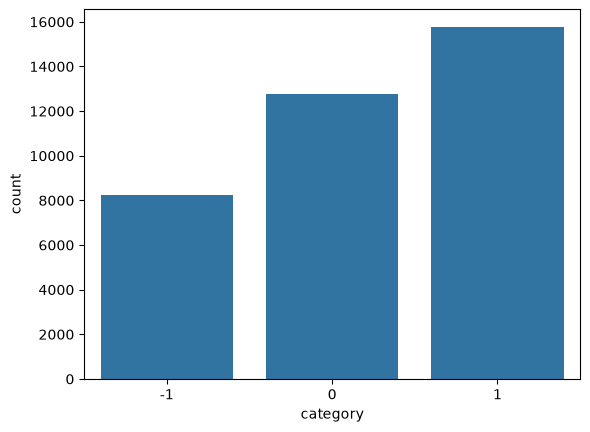

In [26]:
# Distribution of Classes for the categories
# +1 is for positive comments
# -1 is for negative comments
# 0 is for neutral comments

sns.countplot(data = df, x = 'category');

In [27]:
# Frequency distribution of sentiments (percentage distribution)

df['category'].value_counts(normalize=True).mul(100).round(2)

category
 1    42.86
 0    34.71
-1    22.42
Name: proportion, dtype: float64

In [28]:
# Creating a new column to count the words
df['word_count'] = df['clean_comment'].apply(lambda x: len(x.split()))

In [29]:
df.head()

,clean_comment,category,word_count
0,family mormon have never tried explain them th...,1,39
1,buddhism has very much lot compatible with chr...,1,196
2,seriously don say thing first all they won get...,-1,86
3,what you have learned yours and only yours wha...,0,29
4,for your own benefit you may want read living ...,1,112


In [30]:
df.sample(5)

,clean_comment,category,word_count
30990,all from the same day date can verify with dat...,0,20
20700,are you going make another megathread for the ...,0,11
14089,wonder based indian reporter will there from t...,0,10
26544,extremists have shown what frightens them most...,1,12
7394,great stuff keep coming,1,4


In [31]:
df['word_count'].describe()

count    36793.000000
mean        29.667464
std         56.790738
min          1.000000
25%          6.000000
50%         13.000000
75%         30.000000
max       1307.000000
Name: word_count, dtype: float64

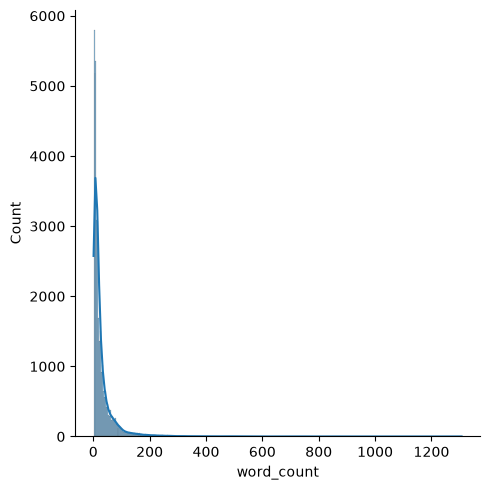

In [32]:
# Distribution plot for the `word_count`
# kde parameter stands for Kernel Density Estimation, which overlays a smooth, continuous curve representing the estimated probability density function of the data. 
sns.displot(df['word_count'], kde=True);

#### Word count Distribution by Category
* Create Figure and axes
* Plot KDE for category 1 (positive comments)
* Plot KDE for category 0 (neutral comments)
* Plot KDE for category -1 (negative comments)
* Add title and labels
- Title = "Word Count Distribution by Category"
- xlabel = "Word Count"
- ylabel = "Density"
* Add a legend
* Show the plot

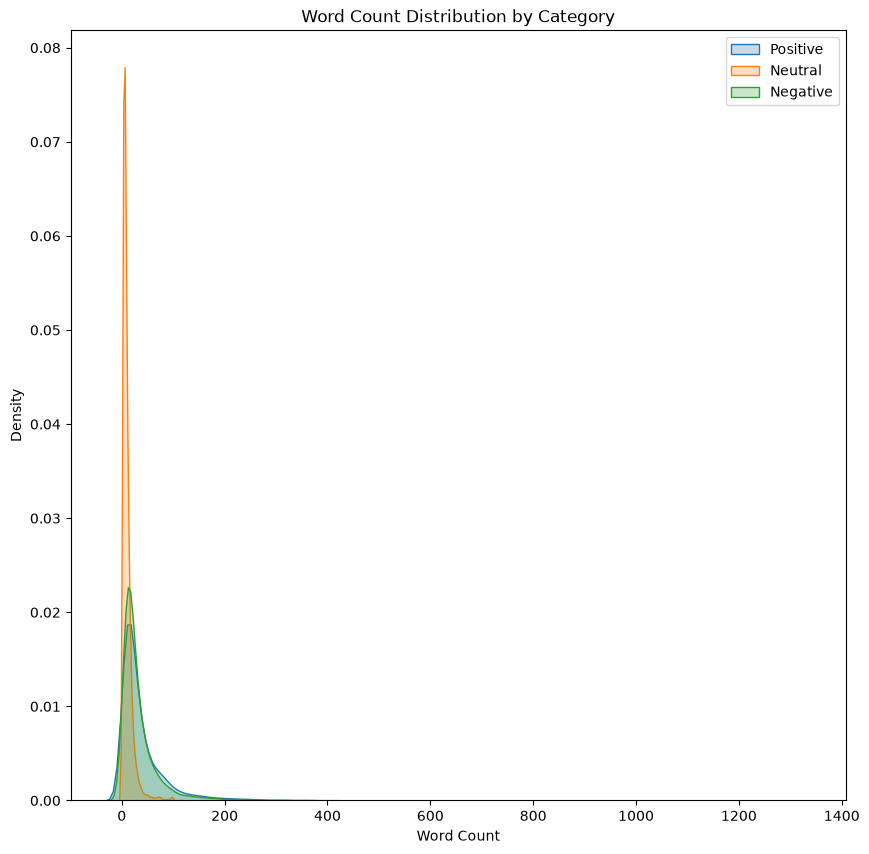

In [33]:
# Create Figure and Axes
plt.figure(figsize=(10, 10))

# Plot KDE for category 1 (positive comments)
sns.kdeplot(df[df['category'] == 1]["word_count"], label="Positive", fill=True)

# Plot KDE for category 1 (positive comments)
sns.kdeplot(df[df['category'] == 0]["word_count"], label="Neutral", fill=True)

# Plot KDE for category 1 (positive comments)
sns.kdeplot(df[df['category'] == -1]["word_count"], label="Negative", fill=True)

# Add Title and Labels
plt.title('Word Count Distribution by Category')
plt.xlabel('Word Count')
plt.ylabel('Density')

# Add a legend
plt.legend()

# Show the plot
plt.show()


### Discussions
**Positive comments (Category 1):** They are having the wider spread in word count, indicating that longer comments are more common in the positive sentiments.

**Neutral comments (Category 0):** The distribution shows a relatively lower frequency and is more concentrated around shorter comments compared to positiver and negative ones.

**Negative comments (Category -1):** These comments have a distribution somewhat similar to positive comments but with a smaller proportion of longer comments.

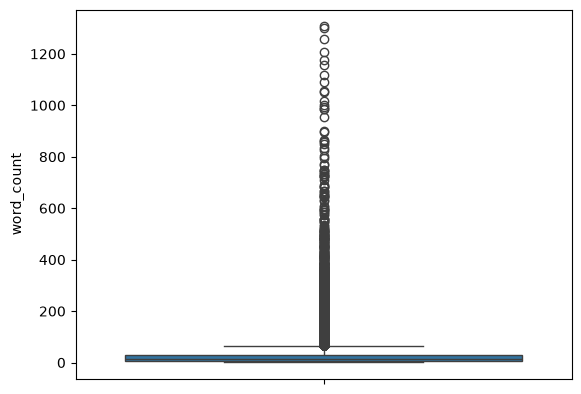

In [34]:
# Plotting Box graph on word count
sns.boxplot(df['word_count']);

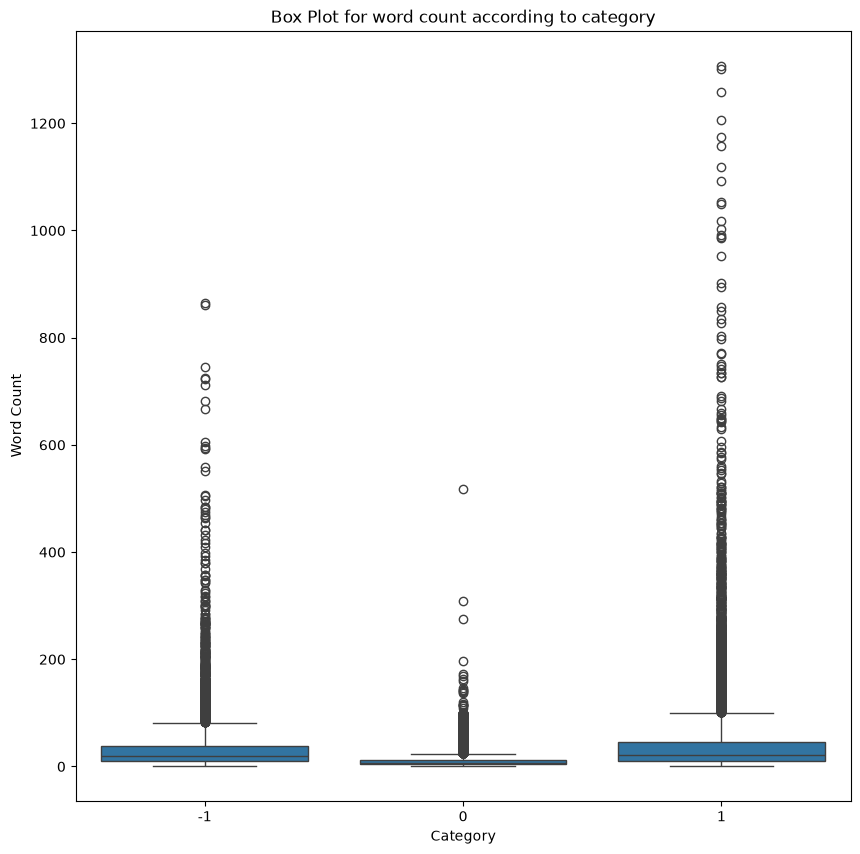

In [35]:
# Plotting a boxplot for the 'word count' column categorized by 'category'
# Defining the figure size
plt.figure(figsize=(10, 10))

# Plotting the boxplot using seaborn
sns.boxplot(data=df, x = "category", y = "word_count")

# Adding titles and labels
plt.title("Box Plot for word count according to category")
plt.xlabel("Category")
plt.ylabel("Word Count")

# Displaying the graph
plt.show()

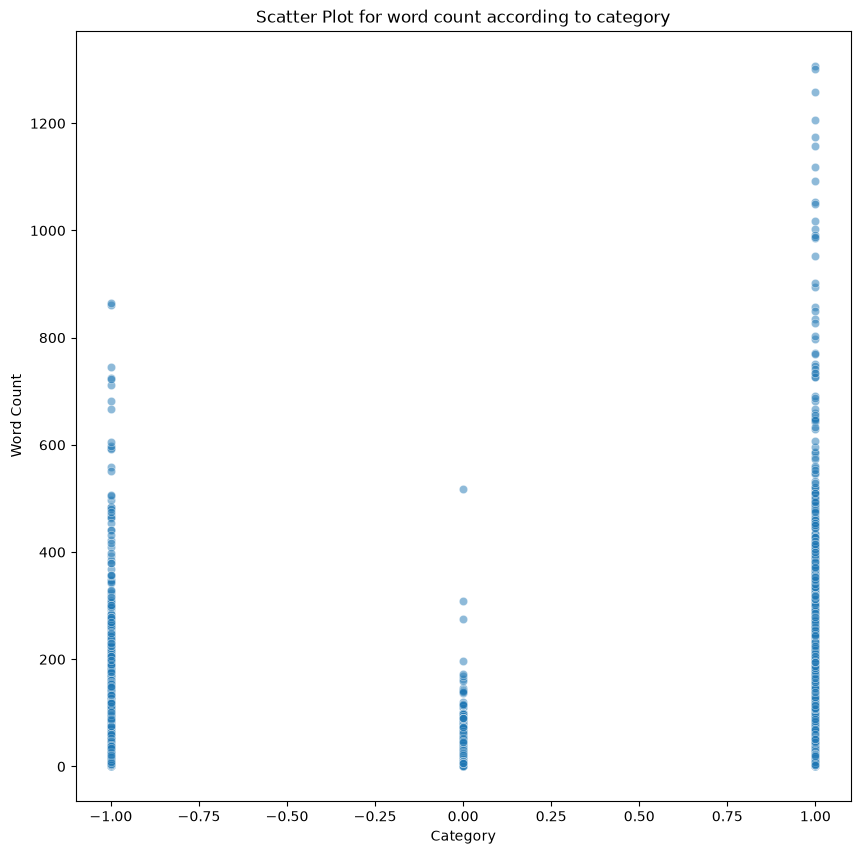

In [36]:
# Plotting a scatter plot for the 'word count' column categorized by 'category'
# Defining the figure size
plt.figure(figsize=(10, 10))

# Plotting the boxplot using seaborn
sns.scatterplot(data=df, x = "category", y = "word_count", alpha=0.5)

# Adding titles and labels
plt.title("Scatter Plot for word count according to category")
plt.xlabel("Category")
plt.ylabel("Word Count")

# Displaying the graph
plt.show()

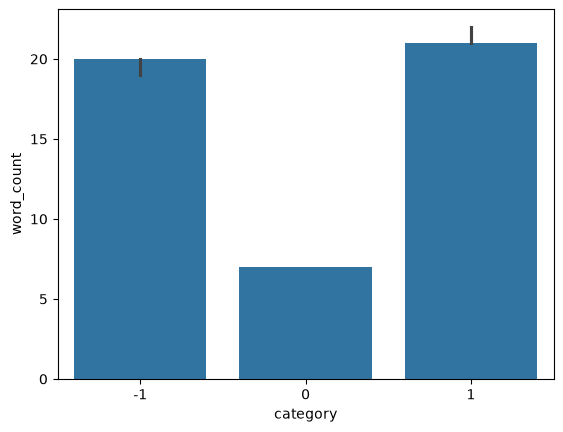

In [37]:
# Plotting a bar plot for median word counts among sentiments
sns.barplot(df, x='category', y='word_count', estimator='median');

## Installed NLTK
NLTK is a leading platform for building Python programs to work with human language data. It provides easy-to-use interfaces to over 50 corpora and lexical resources such as WordNet, along with a suite of text processing libraries for classification, tokenization, stemming, tagging, parsing, and semantic reasoning, wrappers for industrial-strength NLP libraries, and an active discussion forum.

In [38]:
import nltk
from nltk.corpus import stopwords

# If stopwords is not installed in the enviroment, uncomment this
nltk.download("stopwords")

# Define the list of English stopwords
stop_words = set(stopwords.words('english'))

# Create a new column 'num_stop_words' by counting the number of stopwords in each comment
df['num_stop_words'] = df["clean_comment"].apply(lambda x: len([word for word in x.split() if word in stop_words]))

/home/mr-man/Desktop/coding/personal/data-science-lab/env/lib/python3.14/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/mr-man/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):
[nltk_data] Downloading package stopwords to /home/mr-man/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [39]:
df.sample(5)

,clean_comment,category,word_count,num_stop_words
28681,can someone please explain whats written the w...,-1,12,5
27545,kaka again international media proud,1,5,1
36281,urti teer gand kisi kisi leni thi,0,7,0
8770,did not vote for modi 2014 and not identify ri...,1,64,23
31564,source esfg6dm8unu,0,2,0


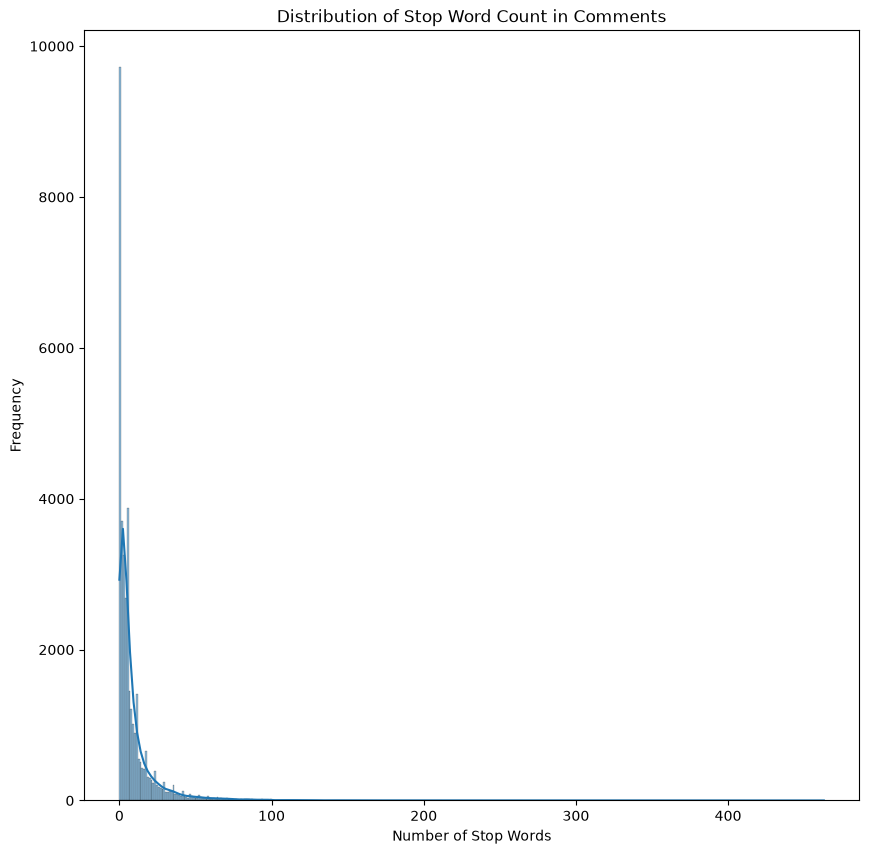

In [40]:
# Plotting a distribution plot for the "num_stop_words" columns
# Define the figure and its size
plt.figure(figsize=(10, 10))

# Plot a histogram graph for the "num_stop_words"
sns.histplot(df["num_stop_words"], kde=True)

# Add title and labels
plt.title("Distribution of Stop Word Count in Comments")
plt.xlabel("Number of Stop Words")
plt.ylabel("Frequency")

# show the graph
plt.show()

#### Stop Words Distribution by Category
* Create Figure and axes
* Plot KDE for category 1 (positive comments)
* Plot KDE for category 0 (neutral comments)
* Plot KDE for category -1 (negative comments)
* Add title and labels
- Title = "Number of Stop Words Distribution by Category"
- xlabel = "Word Count"
- ylabel = "Density"
* Add a legend
* Show the plot

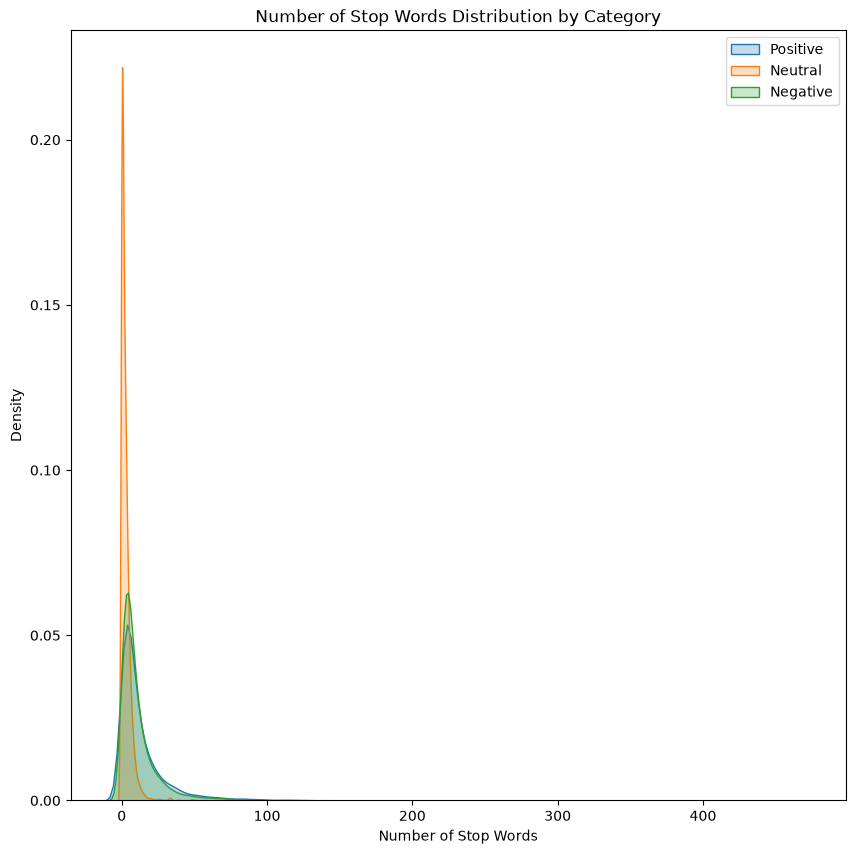

In [41]:
# Create Figure and Axes
plt.figure(figsize=(10, 10))

# Plot KDE for category 1 (positive comments)
sns.kdeplot(df[df['category'] == 1]["num_stop_words"], label="Positive", fill=True)

# Plot KDE for category 1 (positive comments)
sns.kdeplot(df[df['category'] == 0]["num_stop_words"], label="Neutral", fill=True)

# Plot KDE for category 1 (positive comments)
sns.kdeplot(df[df['category'] == -1]["num_stop_words"], label="Negative", fill=True)

# Add Title and Labels
plt.title('Number of Stop Words Distribution by Category')
plt.xlabel('Number of Stop Words')
plt.ylabel('Density')

# Add a legend
plt.legend()

# Show the plot
plt.show()


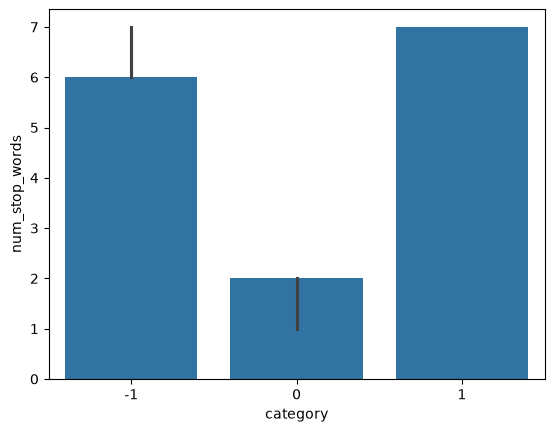

In [42]:
# Plotting a bar plot for median Number of Stop Words among sentiments
sns.barplot(df, x='category', y='num_stop_words', estimator='median');

### Checking the most used stop words from the collection
**Steps:**
1. Create a frequency distribution of stop words in the "clean_comment" column
2. Extract all stop words from teh comments using the defined "num_stop_words"
3. Count the most common stop words
4. Convert the most common stop words to a DataFrame for plotting
5. Create the barplot for the top 30 most common stop words

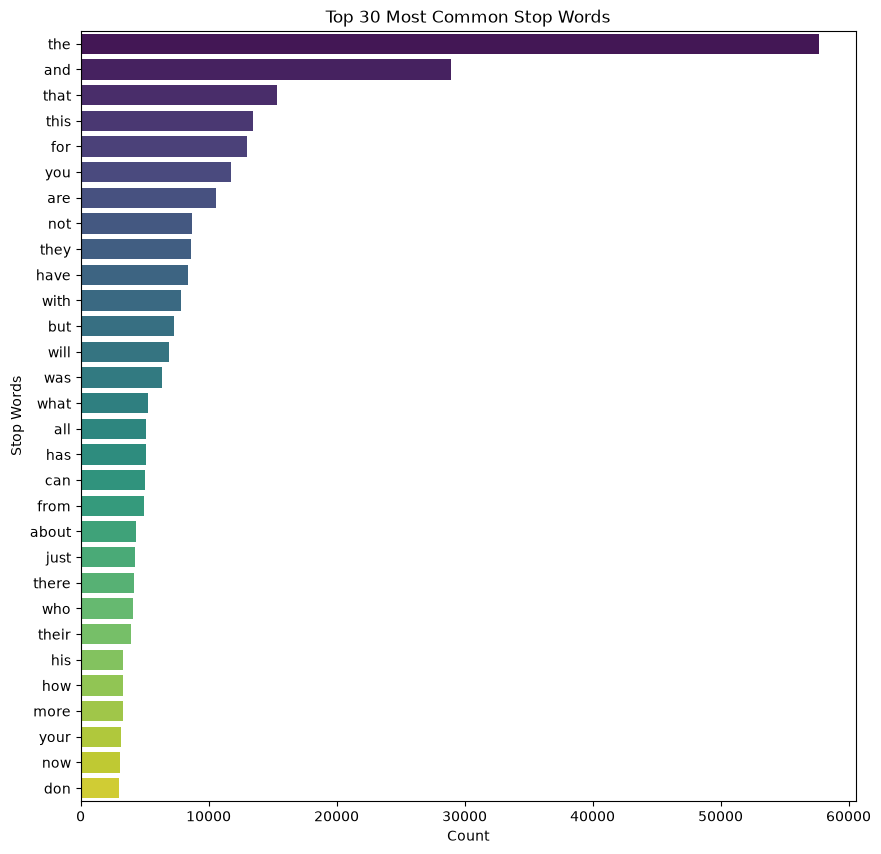

In [43]:
# Create a frequency distribution of stop words in the "clean_comment" column
from collections import Counter

# Extract all stop words from teh comments using the defined "num_stop_words" Here a nested list comprehension was used
# print("Checking all the stop words")
all_stop_words = [word for comment in df["clean_comment"] for word in comment.split() if word in stop_words]
# print(all_stop_words[5])

# Count the most common stop words
# print("Counting the most common stop words")
most_common_stop_words = Counter(all_stop_words).most_common(30)
# print(most_common_stop_words)

# Convert the most common stop words to a DataFrame for plotting
top_30_df = pd.DataFrame(most_common_stop_words, columns=["stop_word", "count"])

# Create the barplot for the top 30 most common stop words
plt.figure(figsize=(10, 10))
sns.barplot(data=top_30_df, x="count", y="stop_word", hue="stop_word", palette="viridis", legend=False )
plt.title("Top 30 Most Common Stop Words")
plt.xlabel("Count")
plt.ylabel("Stop Words")
plt.show()

In [44]:
# Creating column for characters
df["num_characters"] = df["clean_comment"].apply(len)

df.head()

,clean_comment,category,word_count,num_stop_words,num_characters
0,family mormon have never tried explain them th...,1,39,13,259
1,buddhism has very much lot compatible with chr...,1,196,59,1268
2,seriously don say thing first all they won get...,-1,86,40,459
3,what you have learned yours and only yours wha...,0,29,15,167
4,for your own benefit you may want read living ...,1,112,45,690


In [45]:
df["num_characters"].describe()

count    36793.000000
mean       181.852798
std        359.702163
min          1.000000
25%         38.000000
50%         80.000000
75%        184.000000
max       8664.000000
Name: num_characters, dtype: float64

### Checking the individual Special Characters
**STEPS:**
1. Combine all comments into one large string
2. Count the frequency of each character
3. Convert the character frequency into a DataFrame for better display

In [46]:
from collections import Counter

# Combine all comments into one large string
all_text = ' '.join(df["clean_comment"])

# Count the frequency of each character
character_frequency = Counter(all_text)

# Convert the character frequency into a DataFrame for better display
character_frequency_dataframe = pd.DataFrame(character_frequency.items(), columns=['character', 'frequency']).sort_values(by="frequency", ascending=False)

In [47]:
character_frequency_dataframe["character"].values

<StringArray>
[' ', 'e', 't', 'a', 'i', 'n', 'o', 's', 'r', 'h',
 ...
 '遥', '则', '豹', '皿', '煮', '唯', '统', '段', '她', '谁']
Length: 1378, dtype: str

In [48]:
df.head()

,clean_comment,category,word_count,num_stop_words,num_characters
0,family mormon have never tried explain them th...,1,39,13,259
1,buddhism has very much lot compatible with chr...,1,196,59,1268
2,seriously don say thing first all they won get...,-1,86,40,459
3,what you have learned yours and only yours wha...,0,29,15,167
4,for your own benefit you may want read living ...,1,112,45,690


In [49]:
character_frequency_dataframe.tail()

,character,frequency
1345,唯,1
1346,统,1
1330,段,1
1331,她,1
1332,谁,1


In [50]:
# Creating a new column "number_punctuation_chars" to count punctuation characters in each comment
df["number_punctuation_chars"] = df["clean_comment"].apply(lambda x: sum(1 for char in x if char in '.,!?;:"\'()[]{}-'))

df.sample(5)

,clean_comment,category,word_count,num_stop_words,num_characters,number_punctuation_chars
32562,bjp won defeat congress terminal stupidity wil...,-1,22,5,136,0
24792,saved your reply for whenever the family whats...,0,12,3,70,0
24926,where’ rogi rapeynath,0,3,0,21,0
8320,man standard league yahoo ppr 6patd who stream...,-1,16,2,96,0
29277,im14andthisisdeep,0,1,0,17,0


In [51]:
df["number_punctuation_chars"].describe()

count    36793.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
Name: number_punctuation_chars, dtype: float64

In [52]:
df.head()

,clean_comment,category,word_count,num_stop_words,num_characters,number_punctuation_chars
0,family mormon have never tried explain them th...,1,39,13,259,0
1,buddhism has very much lot compatible with chr...,1,196,59,1268,0
2,seriously don say thing first all they won get...,-1,86,40,459,0
3,what you have learned yours and only yours wha...,0,29,15,167,0
4,for your own benefit you may want read living ...,1,112,45,690,0


### Checking ngrams using scikit-learn CounterVertorizer
CounterVectorizer: Convert a collection of text documents to a matrix of token counts.

ngram_rangetuple (min_n, max_n), default=(1, 1)
The lower and upper boundary of the range of n-values for different word n-grams or char n-grams to be extracted. All values of n such such that min_n <= n <= max_n will be used. For example an ngram_range of (1, 1) means only unigrams, (1, 2) means unigrams and bigrams, and (2, 2) means only bigrams. Only applies if analyzer is not callable.

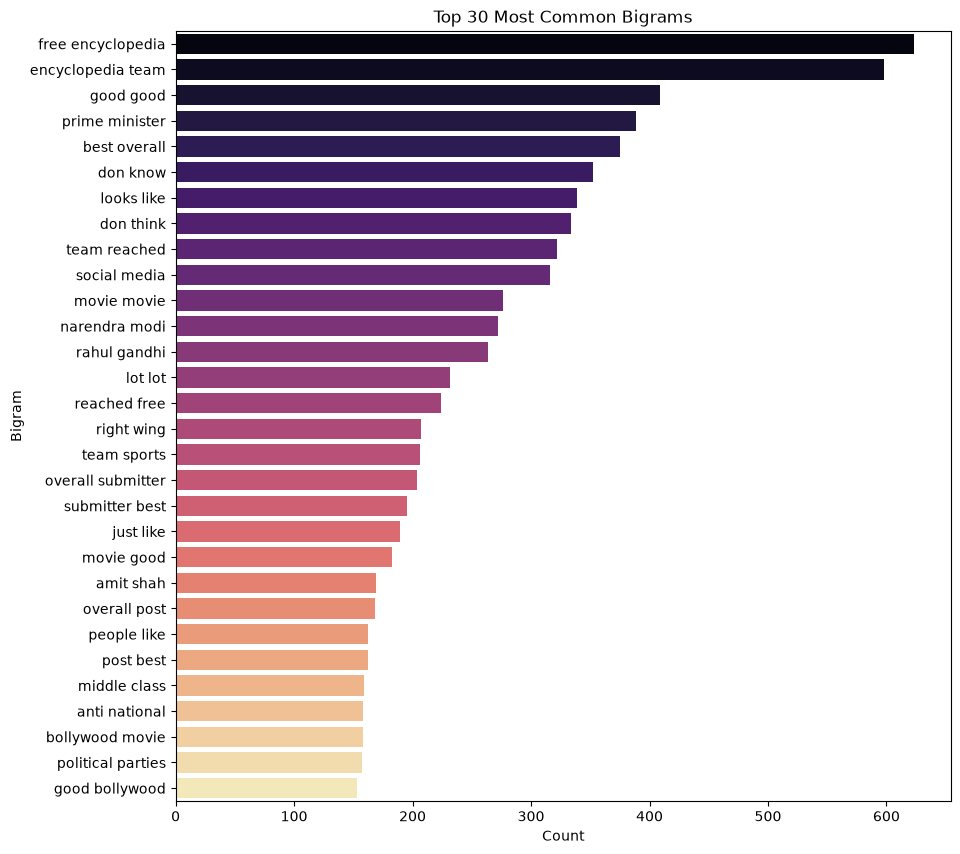

In [53]:
from sklearn.feature_extraction.text import CountVectorizer

# Create a function to extract the top 30 bigrams
def get_top_ngrams(corpus, n=None):
    vec = CountVectorizer(ngram_range=(2, 2), stop_words="english").fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0)
    words_frequency = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_frequency = sorted(words_frequency, key=lambda x: x[1], reverse=True)
    return words_frequency[:n]

# Get the top 30 bigrams
top_30_bigrams = get_top_ngrams(df["clean_comment"], 30)

# Converting the bigrams into Pandas DataFrame for plotting
top_30_bigrams_df = pd.DataFrame(top_30_bigrams, columns=["bigram", "count"])

# Plot the countplot for the top 30 bigrams
plt.figure(figsize=(10, 10))
sns.barplot(data=top_30_bigrams_df, x='count', y='bigram', hue="bigram", palette='magma', legend=False)
plt.title("Top 30 Most Common Bigrams")
plt.xlabel("Count")
plt.ylabel("Bigram")
plt.show()

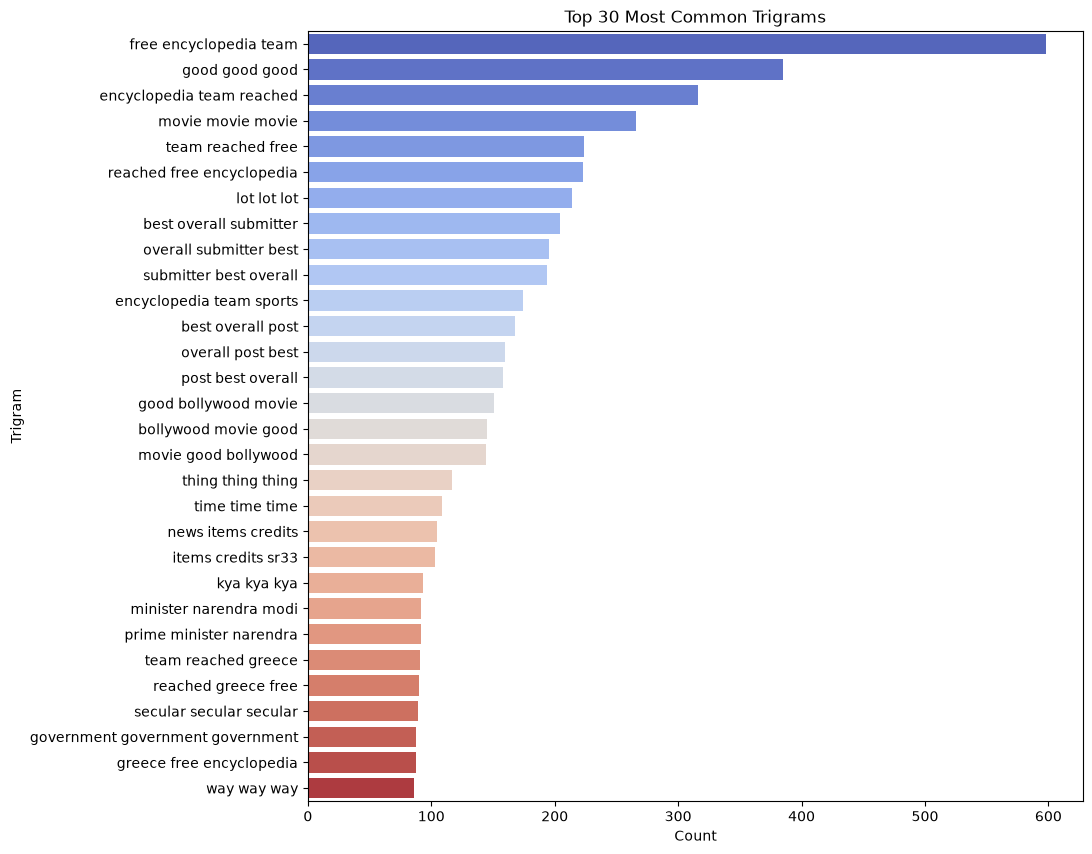

In [54]:
# Create a function to extract the top 30 bigrams
def get_top_trigrams(corpus, n=None):
    vec = CountVectorizer(ngram_range=(3, 3), stop_words="english").fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0)
    words_frequency = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_frequency = sorted(words_frequency, key=lambda x: x[1], reverse=True)
    return words_frequency[:n]

# Get the top 30 trigrams
top_30_trigrams = get_top_trigrams(df["clean_comment"], 30)

# Converting the trigrams into Pandas DataFrame for plotting
top_30_trigrams_df = pd.DataFrame(top_30_trigrams, columns=["trigram", "count"])

# Plot the countplot for the top 30 trigrams
plt.figure(figsize=(10, 10))
sns.barplot(data=top_30_trigrams_df, x='count', y='trigram', hue="trigram", palette='coolwarm', legend=False)
plt.title("Top 30 Most Common Trigrams")
plt.xlabel("Count")
plt.ylabel("Trigram")
plt.show()

In [55]:
# Remove non-English characters from the "clean_comment" column. 
# Keeping only standard English letters, digits, and common punctuations.

import re
df["clean_comment"] = df["clean_comment"].apply(lambda x: re.sub(r'[^A-Za-z0-9\s!?.,]', '', str(x)))

In [56]:
# Checking the characters now

all_text = " ".join(df["clean_comment"])

# Count the frequency of each character
character_frequency = Counter(all_text)

# Convert the character frequency into a DataFrame for better display
character_frequency_df = pd.DataFrame(character_frequency.items(), columns=["character", "frequency"]).sort_values(by='frequency', ascending=False)

character_frequency_df

,character,frequency
6,,1091592
12,e,666610
13,t,491287
1,a,481134
3,i,401388
9,n,388465
7,o,379908
17,s,355279
8,r,331425
10,h,296748


In [57]:
from nltk.corpus import stopwords

# Defining stop words and keeping the essential ones for sentiment analysus
stop_words = set(stopwords.words('english')) - {"not", "but", "however", "no", "yet"}

# Remove stop words from "clean_comment" column, retaining essential ones
df["clean_comment"] = df["clean_comment"].apply(lambda x: " ".join([word for word in x.split() if word.lower() not in stop_words]))

In [58]:
df.head()

,clean_comment,category,word_count,num_stop_words,num_characters,number_punctuation_chars
0,family mormon never tried explain still stare ...,1,39,13,259,0
1,buddhism much lot compatible christianity espe...,1,196,59,1268,0
2,seriously say thing first get complex explain ...,-1,86,40,459,0
3,learned want teach different focus goal not wr...,0,29,15,167,0
4,benefit may want read living buddha living chr...,1,112,45,690,0


### Lamatizer
words like play, plays, playing, played are to be considered as one

In [59]:
from nltk.stem import WordNetLemmatizer

nltk.download('wordnet')
# Define the lemmatizer
lemmatizer = WordNetLemmatizer()

# Apply lemmatization to the "clean_comment_no_stopwords" column
df["clean_comment"] = df["clean_comment"].apply(lambda x: " ".join([lemmatizer.lemmatize(word) for word in x.split()]))

df.head()

/home/mr-man/Desktop/coding/personal/data-science-lab/env/lib/python3.14/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/mr-man/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):
[nltk_data] Downloading package wordnet to /home/mr-man/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


,clean_comment,category,word_count,num_stop_words,num_characters,number_punctuation_chars
0,family mormon never tried explain still stare ...,1,39,13,259,0
1,buddhism much lot compatible christianity espe...,1,196,59,1268,0
2,seriously say thing first get complex explain ...,-1,86,40,459,0
3,learned want teach different focus goal not wr...,0,29,15,167,0
4,benefit may want read living buddha living chr...,1,112,45,690,0


In [63]:
# Creating Word Cloud for all the clean_comment
from wordcloud import WordCloud
import matplotlib.pyplot as plt

def plot_word_cloud(text, title="Word Cloud for clean comment"):
    # Changed background_colour to background_color
    wordcloud = WordCloud(width=800, height=400, background_color="white").generate(" ".join(text))
    plt.figure(figsize=(10, 5))
    plt.title(title)
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis('off')
    plt.show()

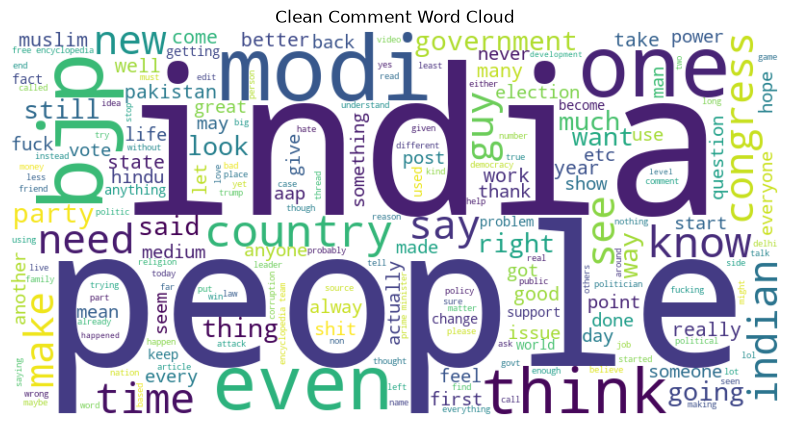

In [64]:
plot_word_cloud(df['clean_comment'], "Clean Comment Word Cloud")

In [67]:
df

,clean_comment,category,word_count,num_stop_words,num_characters,number_punctuation_chars
0,family mormon never tried explain still stare ...,1,39,13,259,0
1,buddhism much lot compatible christianity espe...,1,196,59,1268,0
2,seriously say thing first get complex explain ...,-1,86,40,459,0
3,learned want teach different focus goal not wr...,0,29,15,167,0
4,benefit may want read living buddha living chr...,1,112,45,690,0
...,...,...,...,...,...,...
37244,jesus,0,1,0,5,0
37245,kya bhai pure saal chutiya banaya modi aur jab...,1,19,0,99,0
37246,downvote karna tha par upvote hogaya,0,6,0,36,0
37247,haha nice,1,2,0,9,0


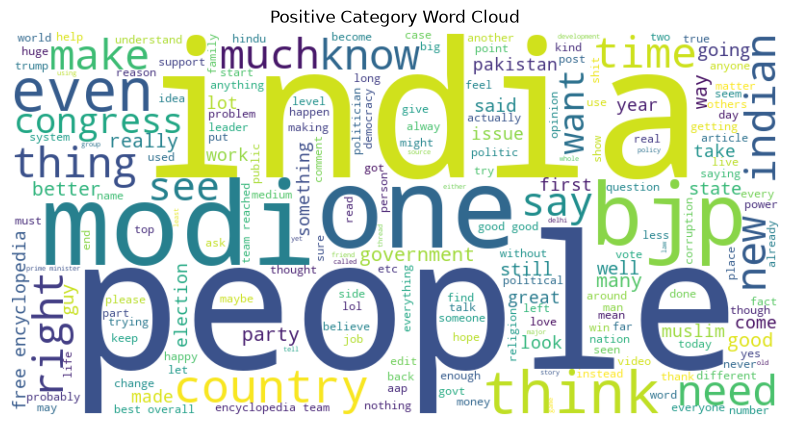

In [68]:
plot_word_cloud(df[df['category'] == 1]["clean_comment"], "Positive Category Word Cloud")

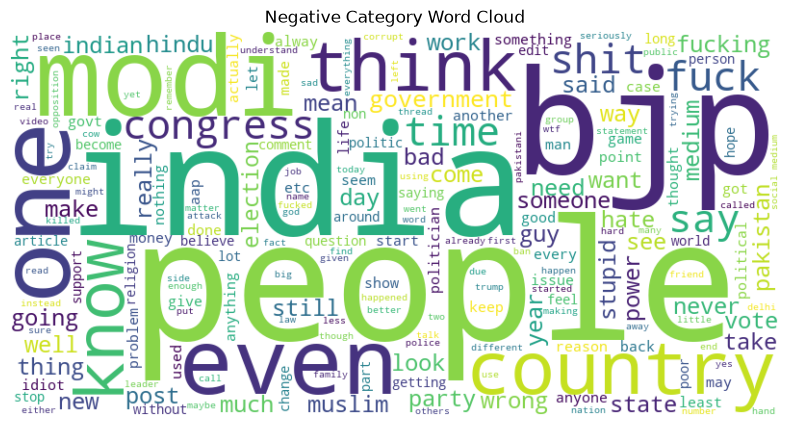

In [69]:
plot_word_cloud(df[df['category'] == -1]["clean_comment"], "Negative Category Word Cloud")

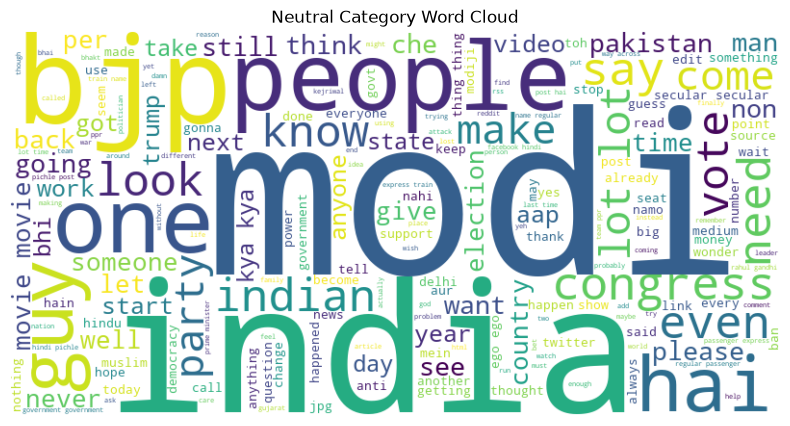

In [70]:
plot_word_cloud(df[df['category'] == 0]["clean_comment"], "Neutral Category Word Cloud")

#### Checking the most frequent used words
* Define a function plot_top_n_words. The function will receive data and the n number of words to check, default number is 20
* In the function, flatten all words in the comments column
* Get the top N most common words
* Split the words and their counts for plotting
* Plot the top N words

In [72]:
def plot_top_n_words(df, n=25):
    """Plot the top N most frequent words in the dataset."""
    # Flatten all words in the comments column
    words = ' '.join(df['clean_comment']).split()

    # Get the top N most common words
    counter = Counter(words)
    most_common_words = counter.most_common(n)

    # Split the words and their counts for plotting
    words, counts = zip(*most_common_words)

    # Plot the top N words using
    plt.figure(figsize=(10, 10))
    sns.barplot(x=list(counts), y=list(words))
    plt.title(f'Top {n} Most Frequent Words')
    plt.xlabel("Frequency")
    plt.ylabel("Words")
    plt.show()
    

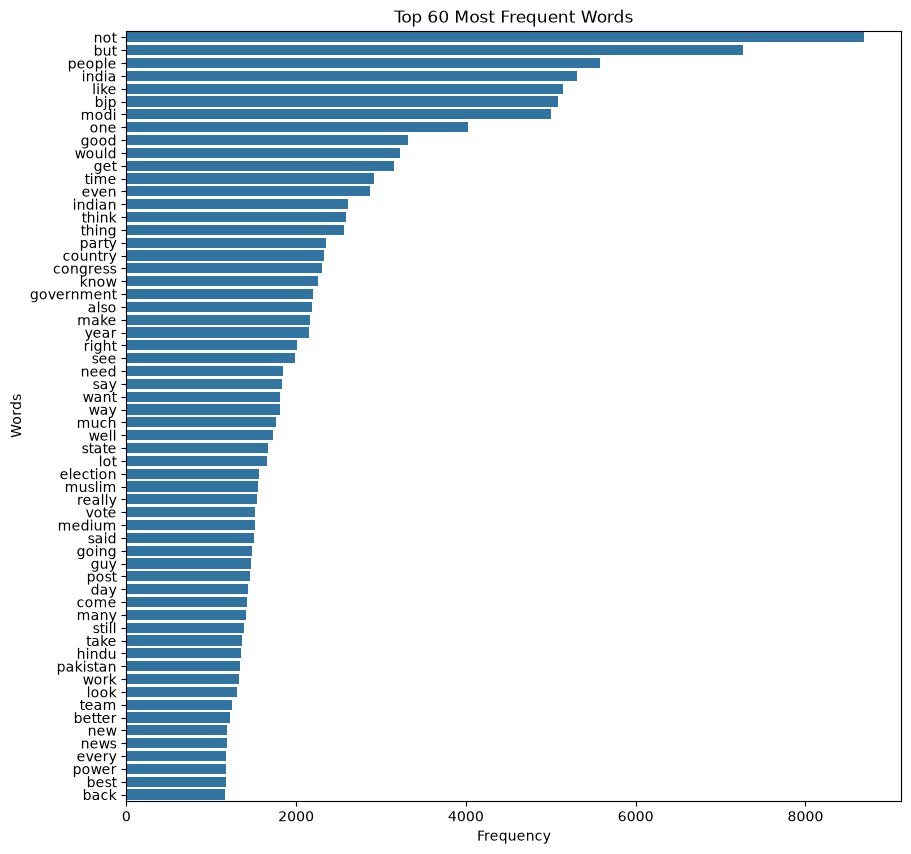

In [73]:
plot_top_n_words(df, n=60)

##### Checking Most common used words according to category

In [81]:
def plot_top_n_words_by_category(df, n=25, start=0):
    """Plot the top N most frequent words in the dataset with stacked hue based on sentiment category."""
    # Flatten all words in the comment and count their occurrences by category
    word_category_counts = {}

    for idx, row in df.iterrows():
        words = row['clean_comment'].split()
        category = row['category'] # Assuming 'category' column exists for -1, 0, 1 labels

        for word in words:
            if word not in word_category_counts:
                word_category_counts[word] = {-1: 0, 0:0, 1:0} # Initialize counts for each sentiment category

            # Increment the count for the corresponding sentiment category
            word_category_counts[word][category] += 1

    # Get total counts across all categories for each word
    total_word_counts = {word: sum(counts.values()) for word, counts in word_category_counts.items()}

    # Get the top N most frequent words across allcategories
    most_common_words = sorted(total_word_counts.items(), key=lambda x: x[1], reverse=True)[start: start + n]
    top_words = [word for word, _ in most_common_words]

    # Prepare data for plotting
    word_labels = top_words
    negative_counts = [word_category_counts[word][-1] for word in top_words]
    neutral_counts = [word_category_counts[word][0] for word in top_words]
    positive_counts = [word_category_counts[word][1] for word in top_words]

    # Plot the stacked bar chart
    plt.figure(figsize=(12, 8))
    bar_width = 0.75

    # Plot negative, neutral, and positive counts in stacked manner
    plt.barh(word_labels, negative_counts, color='red', label="Negative (-1)", height=bar_width)
    plt.barh(word_labels, neutral_counts, left=negative_counts, color='gray', label="Neutral (0)", height=bar_width)
    combined_left = [i + j for i, j in zip(negative_counts, neutral_counts)]
    plt.barh(word_labels, positive_counts, left=combined_left, color='green', label="Positive (1)", height=bar_width)

    plt.xlabel("Frequency")
    plt.ylabel("Words")
    plt.title(f'Top {n} Most Frequent Words with Stacked Sentiment Categories')
    plt.legend(title="Sentiment", loc='lower right')
    plt.gca().invert_yaxis() # Invert y-axis to show the highest frequency at the top
    plt.show()

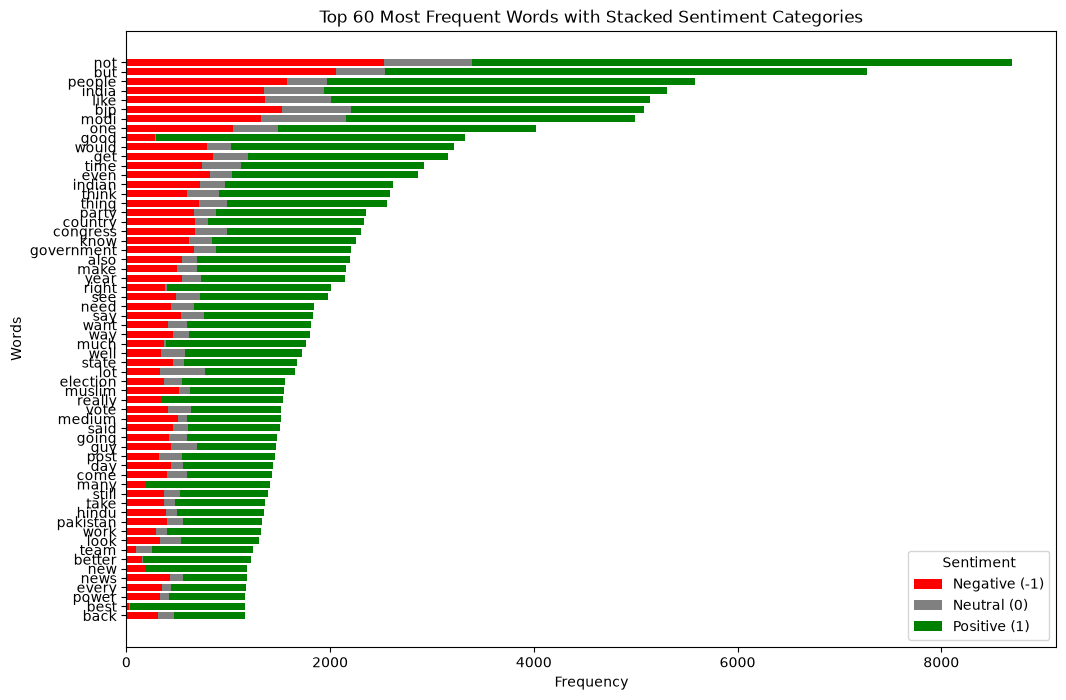

In [82]:
plot_top_n_words_by_category(df, n=60)